In [1]:
# ============================================================
# 05 · Cell 1 — Setup and load all results
# ============================================================
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

SRC_DIR = Path.cwd() / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from commodity_factors.analytics import PerformanceReport, newey_west_tstat
from commodity_factors.config import PATHS, UNIVERSE, Sector

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

PRIMARY_FACTORS = ["mom_12_1", "carry", "value", "skewness", "hedging_pressure", "tsmom_12"]
HEADLINE_COST_BPS = 5
TABLES_DIR = PATHS.root / "reports" / "tables"


def load(name: str) -> pd.DataFrame:
    return pd.read_parquet(PATHS.processed / f"{name}.parquet")


factor_returns = load("factor_returns_headline")[PRIMARY_FACTORS]
factor_gross = load("factor_returns_gross")[PRIMARY_FACTORS]
long_legs = load("factor_long_legs")
short_legs = load("factor_short_legs")
variant_returns = load("variant_returns_net")
robustness_returns = load("robustness_returns_net")
long_only_excess = load("long_only_excess")
factor_weights = load("factor_weights")
regimes = load("regimes")
benchmarks = load("benchmarks_monthly")
monthly_returns = load("returns_monthly")
daily_returns = load("returns_daily")
signal_panel = load("signals")

benchmarks = benchmarks.loc[: factor_returns.index.max()]
ew_benchmark = benchmarks["EW_all"]

print(f"Factor returns : {factor_returns.index.min():%Y-%m} -> {factor_returns.index.max():%Y-%m}, "
      f"{factor_returns.shape[1]} primary factors (net of {HEADLINE_COST_BPS} bps incl. rolls)")
print(f"Variants       : {variant_returns.shape[1]} series | Robustness: {robustness_returns.shape[1]} series")
print(f"Long-only      : {long_only_excess.shape[1]} excess-return series")
print(f"Regimes        : {regimes.shape[1]} indicators")
print(f"Weights        : {factor_weights.columns.get_level_values('factor').nunique()} factors\n")

print("Headline check (should match notebook 04 Cell 11)")
print(PerformanceReport(factor_returns).table()[["start", "months", "sharpe", "t_stat_nw"]]
      .to_string(float_format=lambda x: f"{x:.2f}"))

Factor returns : 2002-02 -> 2026-09, 6 primary factors (net of 5 bps incl. rolls)
Variants       : 20 series | Robustness: 10 series
Long-only      : 5 excess-return series
Regimes        : 6 indicators
Weights        : 6 factors

Headline check (should match notebook 04 Cell 11)
                    start months sharpe t_stat_nw
mom_12_1          2002-02    296   0.11      0.62
carry             2002-02    296   0.17      0.97
value             2005-11    251   0.44      2.12
skewness          2002-02    296   0.46      2.13
hedging_pressure  2002-02    296   0.34      1.44
tsmom_12          2002-02    296   0.40      2.03


Correlation of monthly net factor returns
                  mom_12_1  carry  value  skewness  hedging_pressure  tsmom_12
mom_12_1              1.00   0.28  -0.38      0.05              0.20      0.59
carry                 0.28   1.00   0.05      0.07              0.21      0.16
value                -0.38   0.05   1.00     -0.06             -0.14     -0.38
skewness              0.05   0.07  -0.06      1.00              0.19      0.10
hedging_pressure      0.20   0.21  -0.14      0.19              1.00      0.16
tsmom_12              0.59   0.16  -0.38      0.10              0.16      1.00 

Performance from 2004-02 (net of 5 bps incl. rolls)
                             start months ann_return_% ann_vol_% sharpe t_stat_nw max_dd_%  skew hit_rate_%
mom_12_1                   2004-02    272         2.83     18.41   0.15      0.79   -65.66 -0.17      51.10
carry                      2004-02    272         3.39     17.98   0.19      1.00   -66.01 -0.38      52.94
value                      

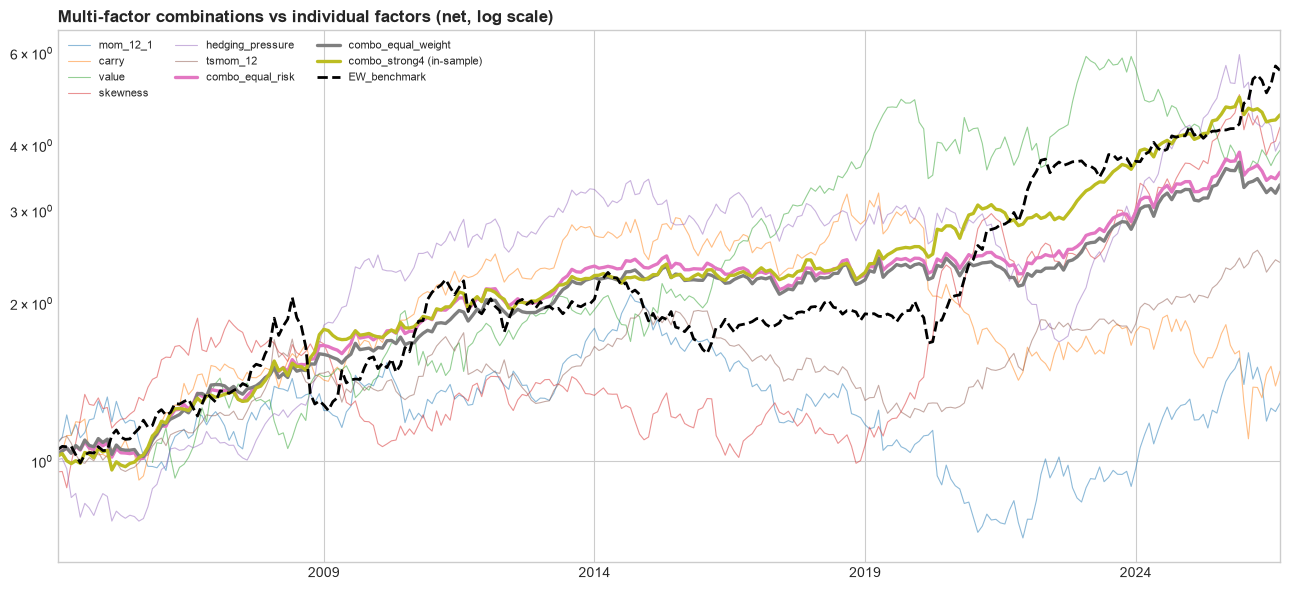

In [2]:
# ============================================================
# 05 · Cell 2 — Correlations, subperiods and multi-factor combination
# ============================================================
VOL_WINDOW = 36
STRONG4 = ["value", "skewness", "hedging_pressure", "tsmom_12"]


def equal_risk_combination(returns: pd.DataFrame, window: int = VOL_WINDOW) -> pd.Series:
    """Weights proportional to 1 / trailing volatility (lagged one month), summing to 1."""
    trailing_vol = returns.rolling(window, min_periods=24).std().shift(1)
    inverse = (1 / trailing_vol).where(returns.notna())
    weights = inverse.div(inverse.sum(axis=1), axis=0)
    return (weights * returns).sum(axis=1, min_count=1)


combos = pd.DataFrame(
    {
        "combo_equal_risk": equal_risk_combination(factor_returns[PRIMARY_FACTORS]),
        "combo_equal_weight": factor_returns[PRIMARY_FACTORS].mean(axis=1),
        "combo_strong4 (in-sample)": equal_risk_combination(factor_returns[STRONG4]),
    }
).dropna()

# 1. Correlation matrix of factor returns
print("Correlation of monthly net factor returns")
print(factor_returns.corr().round(2).to_string(), "\n")

# 2. Performance: factors, combinations, benchmark (combination start onwards)
start = combos.index.min()
everything = pd.concat(
    [factor_returns.loc[start:], combos, ew_benchmark.loc[start:].rename("EW_benchmark")], axis=1
)
columns = ["start", "months", "ann_return_%", "ann_vol_%", "sharpe", "t_stat_nw", "max_dd_%", "skew",
           "hit_rate_%"]
print(f"Performance from {start:%Y-%m} (net of {HEADLINE_COST_BPS} bps incl. rolls)")
print(PerformanceReport(everything).table()[columns].to_string(float_format=lambda x: f"{x:.2f}"), "\n")

avg_factor_vol = factor_returns.loc[start:].std().mean()
print(f"Diversification ratio (avg factor vol / equal-risk combo vol): "
      f"{avg_factor_vol / combos['combo_equal_risk'].std():.2f}\n")

# 3. Subperiod Sharpe ratios
SUBPERIODS = {"2002-2008": ("2002", "2008"), "2009-2015": ("2009", "2015"), "2016-2026": ("2016", "2026")}
subperiod_sharpe = pd.DataFrame(
    {
        label: everything.loc[a:b].apply(lambda r: r.mean() / r.std() * np.sqrt(12))
        for label, (a, b) in SUBPERIODS.items()
    }
)
print("Sharpe ratio by subperiod")
print(subperiod_sharpe.round(2).to_string(), "\n")

# 4. Long-only multi-factor tilt (equal parts of each top-tercile basket)
lo_combo = long_only_excess.mean(axis=1).dropna()
print("Long-only multi-factor tilt vs equal-weight benchmark")
print(f"  excess return  : {lo_combo.mean() * 1200:.2f}% per year")
print(f"  tracking error : {lo_combo.std() * np.sqrt(12) * 100:.2f}%")
print(f"  info ratio     : {lo_combo.mean() / lo_combo.std() * np.sqrt(12):.2f}")
print(f"  t-stat (NW)    : {newey_west_tstat(lo_combo):.2f}")
print(f"  months beating : {lo_combo.gt(0).mean() * 100:.1f}%")

# 5. Chart
fig, ax = plt.subplots(figsize=(13, 6))
for name in everything.columns:
    wealth = (1 + everything[name].dropna()).cumprod()
    if name.startswith("combo"):
        wealth.plot(ax=ax, lw=2.4, label=name)
    elif name == "EW_benchmark":
        wealth.plot(ax=ax, lw=2, ls="--", color="black", label=name)
    else:
        wealth.plot(ax=ax, lw=0.8, alpha=0.5, label=name)
ax.set_yscale("log")
ax.set_title("Multi-factor combinations vs individual factors (net, log scale)", loc="left", fontweight="bold")
ax.legend(ncol=3, fontsize=8, loc="upper left")
ax.set_xlabel("")
fig.tight_layout()
fig.savefig(PATHS.figures / "05_combinations.png", dpi=150)
plt.show()

In [3]:
%%writefile -a src/commodity_factors/analytics.py


def ols_newey_west(
    y: pd.Series,
    X: pd.DataFrame,
    lags: int | None = None,
    add_constant: bool = True,
) -> tuple[pd.DataFrame, dict]:
    """OLS with Newey-West (Bartlett kernel) standard errors.

    Returns a table of coefficients, standard errors and t-statistics (the constant
    is labelled 'alpha', in the units of y), plus the sample size and R-squared.
    Rows with any missing value are dropped.
    """
    data = pd.concat([y.rename("__y__"), X], axis=1).dropna()
    y_values = data["__y__"].to_numpy()
    regressors = data.drop(columns="__y__")
    if add_constant:
        regressors.insert(0, "alpha", 1.0)
    X_values = regressors.to_numpy()

    n = len(y_values)
    lags = lags if lags is not None else int(np.floor(4 * (n / 100) ** (2 / 9)))
    xtx_inv = np.linalg.inv(X_values.T @ X_values)
    beta = xtx_inv @ X_values.T @ y_values
    residuals = y_values - X_values @ beta

    scores = X_values * residuals[:, None]
    omega = scores.T @ scores
    for lag in range(1, lags + 1):
        weight = 1 - lag / (lags + 1)
        gamma = scores[lag:].T @ scores[:-lag]
        omega += weight * (gamma + gamma.T)
    covariance = xtx_inv @ omega @ xtx_inv
    std_errors = np.sqrt(np.diag(covariance))

    table = pd.DataFrame(
        {"coef": beta, "se": std_errors, "t_stat": beta / std_errors}, index=regressors.columns
    )
    return table, {"n": n, "r2": 1 - residuals.var() / y_values.var()}

Appending to src/commodity_factors/analytics.py


In [4]:
# ============================================================
# 05 · Cell 4 — Spanning regressions (market exposure and redundancy)
# ============================================================
from commodity_factors.analytics import ols_newey_west

market = ew_benchmark.rename("EW_benchmark")
series = {name: factor_returns[name] for name in PRIMARY_FACTORS}
series["combo_equal_risk"] = combos["combo_equal_risk"]

# Test A: each factor on the commodity market
test_a = {}
for name, y in series.items():
    table, info = ols_newey_west(y, market.to_frame())
    test_a[name] = {
        "alpha_ann_%": table.at["alpha", "coef"] * 1200,
        "t_alpha": table.at["alpha", "t_stat"],
        "beta_market": table.at["EW_benchmark", "coef"],
        "t_beta": table.at["EW_benchmark", "t_stat"],
        "r2": info["r2"],
        "months": info["n"],
    }
print("Test A: factor = alpha + beta x EW commodity benchmark")
print(pd.DataFrame(test_a).T.to_string(float_format=lambda x: f"{x:.2f}"), "\n")

# Test B: each factor on the other five factors + market
test_b, betas, beta_t = {}, {}, {}
for name in PRIMARY_FACTORS:
    others = [f for f in PRIMARY_FACTORS if f != name]
    X = pd.concat([factor_returns[others], market], axis=1)
    table, info = ols_newey_west(factor_returns[name], X)
    test_b[name] = {
        "alpha_ann_%": table.at["alpha", "coef"] * 1200,
        "t_alpha": table.at["alpha", "t_stat"],
        "r2": info["r2"],
        "months": info["n"],
    }
    betas[name] = table["coef"].drop("alpha")
    beta_t[name] = table["t_stat"].drop("alpha")

print("Test B: factor = alpha + betas x (other five factors + EW benchmark), common sample")
print(pd.DataFrame(test_b).T.to_string(float_format=lambda x: f"{x:.2f}"), "\n")

print("Test B loadings (rows = dependent factor, columns = regressors)")
print(pd.DataFrame(betas).T.round(2).to_string(), "\n")
print("Test B loading t-stats")
print(pd.DataFrame(beta_t).T.round(1).to_string())

pd.DataFrame(test_a).T.to_csv(TABLES_DIR / "05_spanning_market.csv")
pd.DataFrame(test_b).T.to_csv(TABLES_DIR / "05_spanning_factors.csv")

Test A: factor = alpha + beta x EW commodity benchmark
                  alpha_ann_%  t_alpha  beta_market  t_beta   r2  months
mom_12_1                 2.45     0.74        -0.03   -0.30 0.00  296.00
carry                    1.93     0.56         0.11    1.08 0.01  296.00
value                    8.46     1.96        -0.02   -0.15 0.00  251.00
skewness                 8.26     2.12        -0.02   -0.17 0.00  296.00
hedging_pressure         6.23     1.65        -0.06   -0.52 0.00  296.00
tsmom_12                 2.62     1.16         0.24    2.07 0.06  296.00
combo_equal_risk         5.32     3.35         0.08    1.40 0.01  272.00 

Test B: factor = alpha + betas x (other five factors + EW benchmark), common sample
                  alpha_ann_%  t_alpha   r2  months
mom_12_1                 1.37     0.47 0.46  251.00
carry                   -2.39    -0.60 0.16  251.00
value                   10.70     2.87 0.22  251.00
skewness                 3.70     0.80 0.09  251.00
hedging_pressur

C:\Users\navon\AppData\Local\Temp\ipykernel_3956\1014395135.py:29: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  X = pd.concat([factor_returns[others], market], axis=1)
C:\Users\navon\AppData\Local\Temp\ipykernel_3956\1014395135.py:29: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  X = pd.concat([factor_returns[others], market], axis=1)
C:\Users\navon\AppData\Local\Temp\ipykernel_3956\1014395135.py:29: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In 

In [5]:
# ============================================================
# 05 · Cell 5 — Robustness: cap daily returns at +/-20% and rebuild
# ============================================================
from commodity_factors.contracts import CONTRACT_SPECS
from commodity_factors.portfolio import Backtester, QuantileLongShort, VolScaledTimeSeries
from commodity_factors.risk import EWMAVolatility
from commodity_factors.signals import MomentumSignal, SkewnessSignal, TimeSeriesMomentumSignal

CAP = 0.20
BACKTEST_START = "2002-01-31"
LAST_MONTH = factor_returns.index.max()

# 1. Capped returns
capped_daily = daily_returns.clip(lower=-CAP, upper=CAP)
print(f"Daily returns capped: {int((daily_returns.abs() > CAP).sum().sum())} of "
      f"{int(daily_returns.notna().sum().sum()):,}\n")

valid_days = capped_daily.resample("ME").count()
capped_monthly = np.expm1(np.log1p(capped_daily).resample("ME").sum(min_count=1)).where(valid_days >= 10)
capped_monthly = capped_monthly.loc[:LAST_MONTH]
capped_index = (1 + capped_daily.fillna(0)).cumprod().mul(100).where(daily_returns.notna().cummax())

# 2. Rebuild return-based signals; reuse the others
capped_signals = {
    "mom_12_1": MomentumSignal(capped_index, lookback=12, skip=1).compute(),
    "carry": signal_panel["carry"],
    "value": signal_panel["value"],
    "skewness": SkewnessSignal(capped_daily).compute(),
    "hedging_pressure": signal_panel["hedging_pressure"],
    "tsmom_12": TimeSeriesMomentumSignal(capped_index, lookback=12).compute(),
}
capped_signals = {name: sig.loc[:LAST_MONTH] for name, sig in capped_signals.items()}
capped_vol = EWMAVolatility(capped_daily).compute()

# 3. Rebuild portfolios with the same construction and costs
rolls_per_month = pd.Series({s: len(spec.month_codes) / 12 for s, spec in CONTRACT_SPECS.items()})
capped_backtester = Backtester(capped_monthly, cost_per_turnover=0.0005)


def headline_net(res) -> pd.Series:
    held = res.weights.abs().reindex(columns=rolls_per_month.index).fillna(0.0)
    rolls = (held * rolls_per_month).sum(axis=1).reindex(capped_monthly.index).shift(1)
    total = res.turnover + rolls.reindex(res.gross.index)
    return res.gross - total * HEADLINE_COST_BPS / 10_000


capped_returns = {}
for name in PRIMARY_FACTORS:
    constructor = VolScaledTimeSeries(capped_vol) if name == "tsmom_12" else QuantileLongShort()
    result = capped_backtester.run(constructor.weights(capped_signals[name]), start=BACKTEST_START)
    capped_returns[name] = headline_net(result)
capped_returns = pd.DataFrame(capped_returns)
capped_returns["combo_equal_risk"] = equal_risk_combination(capped_returns[PRIMARY_FACTORS])

original = factor_returns.copy()
original["combo_equal_risk"] = combos["combo_equal_risk"]

# 4. Compare
comparison = {}
for name in original.columns:
    o = PerformanceReport(original[name]).table().iloc[0]
    c = PerformanceReport(capped_returns[name]).table().iloc[0]
    comparison[name] = {
        "sharpe_original": o["sharpe"], "sharpe_capped": c["sharpe"],
        "t_original": o["t_stat_nw"], "t_capped": c["t_stat_nw"],
        "ann_ret_original_%": o["ann_return_%"], "ann_ret_capped_%": c["ann_return_%"],
        "return_corr": original[name].corr(capped_returns[name]),
    }
cap_table = pd.DataFrame(comparison).T
print("Original vs +/-20% capped (net of 5 bps incl. rolls)")
print(cap_table.to_string(float_format=lambda x: f"{x:.2f}"))
cap_table.to_csv(TABLES_DIR / "05_cap_robustness.csv")

Daily returns capped: 34 of 157,044

Original vs +/-20% capped (net of 5 bps incl. rolls)
                  sharpe_original  sharpe_capped  t_original  t_capped  ann_ret_original_%  ann_ret_capped_%  return_corr
mom_12_1                     0.11           0.10        0.62      0.52                2.13              1.81         0.99
carry                        0.17           0.17        0.97      0.94                3.02              2.91         1.00
value                        0.44           0.45        2.12      2.12                8.27              8.26         1.00
skewness                     0.46           0.42        2.13      1.96                8.11              7.05         0.98
hedging_pressure             0.34           0.39        1.44      1.65                5.63              6.28         1.00
tsmom_12                     0.40           0.40        2.03      2.01                4.95              4.96         1.00
combo_equal_risk             0.71           0.71        

In [11]:
# ============================================================
# 05 · Cell 6 — Validation against AQR published factor returns
# ============================================================
from datetime import datetime

import requests

AQR_DIR = PATHS.raw / "aqr"
AQR_DIR.mkdir(parents=True, exist_ok=True)
AQR_FILES = {
    "vme": ("Value-and-Momentum-Everywhere-Factors-Monthly.xlsx",
            "https://www.aqr.com/-/media/AQR/Documents/Insights/Data-Sets/"
            "Value-and-Momentum-Everywhere-Factors-Monthly.xlsx"),
    "tsmom": ("Time-Series-Momentum-Factors-Monthly.xlsx",
              "https://www.aqr.com/-/media/AQR/Documents/Insights/Data-Sets/"
              "Time-Series-Momentum-Factors-Monthly.xlsx"),
}
AQR_COMMODITY_COLUMNS = {
    "aqr_value": ("vme", "VALLS_VME_COM"),
    "aqr_momentum": ("vme", "MOMLS_VME_COM"),
    "aqr_tsmom": ("tsmom", "TSMOM^CM"),
}

# 1. Download (skipped if the file already exists)
for key, (file_name, url) in AQR_FILES.items():
    path = AQR_DIR / file_name
    if not path.exists():
        response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)
        print(f"Downloaded {file_name}")


# 2. Parse: dates may be Excel dates or MM/DD/YYYY text
def to_timestamp(value) -> pd.Timestamp | None:
    if isinstance(value, (pd.Timestamp, datetime)):
        return pd.Timestamp(value)
    if isinstance(value, str):
        try:
            return pd.Timestamp(datetime.strptime(value.strip(), "%m/%d/%Y"))
        except ValueError:
            return None
    return None


def read_aqr(path: Path) -> pd.DataFrame:
    """Monthly returns from the workbook's 'Factors' sheet, indexed by month-end."""
    workbook = pd.ExcelFile(path)
    sheet = next(s for s in workbook.sheet_names if "factors" in s.lower())
    raw = pd.read_excel(workbook, sheet_name=sheet, header=None)

    dates = raw.iloc[:, 0].map(to_timestamp)
    first_data_row = int(dates.notna().to_numpy().argmax())
    columns = raw.iloc[first_data_row - 1].astype(str).str.strip().tolist()
    columns[0] = "date"

    frame = raw.iloc[first_data_row:].copy()
    frame.columns = columns
    frame["date"] = dates.iloc[first_data_row:]
    frame = frame.dropna(subset=["date"])
    frame.index = pd.DatetimeIndex(frame.pop("date")) + pd.offsets.MonthEnd(0)
    return frame.apply(pd.to_numeric, errors="coerce").dropna(how="all", axis=1)


workbooks = {key: read_aqr(AQR_DIR / file_name) for key, (file_name, _) in AQR_FILES.items()}
aqr = pd.DataFrame(
    {label: workbooks[book][column] for label, (book, column) in AQR_COMMODITY_COLUMNS.items()}
)
for label, (book, column) in AQR_COMMODITY_COLUMNS.items():
    valid = aqr[label].dropna()
    print(f"{label:<13} <- {column:<14}: {valid.index.min():%Y-%m} -> {valid.index.max():%Y-%m}")
print()

# 3. Compare with our gross factor returns over the overlapping months
pairs = {"mom_12_1": "aqr_momentum", "value": "aqr_value", "tsmom_12": "aqr_tsmom"}
validation = {}
for ours, theirs in pairs.items():
    both = pd.concat([factor_gross[ours], aqr[theirs]], axis=1, sort=True).dropna()
    validation[f"{ours} vs {theirs}"] = {
        "overlap": f"{both.index.min():%Y-%m} -> {both.index.max():%Y-%m}",
        "months": len(both),
        "correlation": both.corr().iloc[0, 1],
        "our_sharpe": both[ours].mean() / both[ours].std() * np.sqrt(12),
        "aqr_sharpe": both[theirs].mean() / both[theirs].std() * np.sqrt(12),
    }
validation_table = pd.DataFrame(validation).T
print("Our gross factors vs AQR (overlapping months)")
print(validation_table.to_string(float_format=lambda x: f"{x:.2f}"))
validation_table.to_csv(TABLES_DIR / "05_aqr_validation.csv")

aqr_value     <- VALLS_VME_COM : 1972-01 -> 2025-01
aqr_momentum  <- MOMLS_VME_COM : 1972-01 -> 2025-01
aqr_tsmom     <- TSMOM^CM      : 1985-01 -> 2026-05

Our gross factors vs AQR (overlapping months)
                                     overlap months correlation our_sharpe aqr_sharpe
mom_12_1 vs aqr_momentum  2002-02 -> 2025-01    276        0.75       0.18       0.05
value vs aqr_value        2005-11 -> 2025-01    231        0.79       0.55       0.33
tsmom_12 vs aqr_tsmom     2002-02 -> 2026-05    292        0.75       0.48       0.35


In [12]:
# ============================================================
# 05 · Cell 7 — Multiple-testing adjustment
# ============================================================
from math import erfc, sqrt
from statistics import NormalDist

HLZ_THRESHOLD = 3.0


def two_sided_p(t: float) -> float:
    return erfc(abs(t) / sqrt(2))


def holm_adjust(p_values: pd.Series) -> pd.Series:
    """Holm-Bonferroni adjusted p-values (step-down)."""
    order = p_values.sort_values()
    m = len(order)
    adjusted = (order * (m - np.arange(m))).cummax().clip(upper=1.0)
    return adjusted.reindex(p_values.index)


# 1. Primary factors + the pre-specified combination
primary_t = {name: newey_west_tstat(factor_returns[name]) for name in PRIMARY_FACTORS}
combo_t = newey_west_tstat(combos["combo_equal_risk"])
p_primary = pd.Series({name: two_sided_p(t) for name, t in primary_t.items()})

mt_table = pd.DataFrame(
    {
        "t_stat_nw": pd.Series(primary_t),
        "p_value": p_primary,
        "holm_p (6 primary)": holm_adjust(p_primary),
    }
)
mt_table.loc["combo_equal_risk"] = [combo_t, two_sided_p(combo_t), np.nan]
mt_table["passes_5%_unadjusted"] = mt_table["p_value"] < 0.05
mt_table["passes_holm_5%"] = mt_table["holm_p (6 primary)"] < 0.05
mt_table["passes_HLZ_t>3"] = mt_table["t_stat_nw"].abs() > HLZ_THRESHOLD
print("Multiple-testing view of the primary results")
print(mt_table.to_string(float_format=lambda x: f"{x:.3f}"), "\n")

# 2. Every strategy return series tested in notebooks 04-05
all_series = pd.concat([variant_returns, robustness_returns], axis=1, sort=True)
all_series = all_series.loc[:, ~all_series.columns.duplicated()]
all_t = all_series.apply(newey_west_tstat)
m_all = len(all_t)
critical_t = NormalDist().inv_cdf(1 - 0.05 / (2 * m_all))

print(f"All strategies tested: {m_all}")
print(f"  Bonferroni critical |t| at 5%: {critical_t:.2f}")
print(f"  Strategies with |t| > 1.96     : {int((all_t.abs() > 1.96).sum())} "
      f"(about {0.05 * m_all:.1f} expected by chance if none were real)")
print(f"  Strategies passing Bonferroni  : {int((all_t.abs() > critical_t).sum())}")
print(f"  Strategies passing HLZ (t > 3) : {int((all_t.abs() > HLZ_THRESHOLD).sum())}\n")
print("Top 10 strategies by |t|")
print(all_t.reindex(all_t.abs().sort_values(ascending=False).index).head(10).round(2).to_string())

mt_table.to_csv(TABLES_DIR / "05_multiple_testing.csv")

Multiple-testing view of the primary results
                  t_stat_nw  p_value  holm_p (6 primary)  passes_5%_unadjusted  passes_holm_5%  passes_HLZ_t>3
mom_12_1              0.621    0.534               0.662                 False           False           False
carry                 0.972    0.331               0.662                 False           False           False
value                 2.118    0.034               0.201                  True           False           False
skewness              2.125    0.034               0.201                  True           False           False
hedging_pressure      1.438    0.150               0.451                 False           False           False
tsmom_12              2.028    0.043               0.201                  True           False           False
combo_equal_risk      3.910    0.000                 NaN                  True           False            True 

All strategies tested: 30
  Bonferroni critical |t| at 5%: 3.14
 

In [13]:
# ============================================================
# 05 · Cell 8 — Final summary table and save
# ============================================================
headline_stats = PerformanceReport(
    pd.concat([factor_returns, combos[["combo_equal_risk"]]], axis=1, sort=True)
).table()

aqr_corr = {
    "mom_12_1": validation_table.loc["mom_12_1 vs aqr_momentum", "correlation"],
    "value": validation_table.loc["value vs aqr_value", "correlation"],
    "tsmom_12": validation_table.loc["tsmom_12 vs aqr_tsmom", "correlation"],
}
spanning_market = pd.DataFrame(test_a).T
spanning_factors = pd.DataFrame(test_b).T

summary = pd.DataFrame(
    {
        "start": headline_stats["start"],
        "sharpe_net": headline_stats["sharpe"],
        "t_stat_nw": headline_stats["t_stat_nw"],
        "max_dd_%": headline_stats["max_dd_%"],
        "holm_p": mt_table["holm_p (6 primary)"],
        "alpha_vs_market_t": spanning_market["t_alpha"],
        "alpha_vs_factors_t": spanning_factors["t_alpha"],
        "sharpe_capped_20%": cap_table["sharpe_capped"],
        "corr_with_AQR": pd.Series(aqr_corr),
    }
).reindex(PRIMARY_FACTORS + ["combo_equal_risk"])
summary["evidence"] = np.select(
    [
        summary["t_stat_nw"].abs() > HLZ_THRESHOLD,
        summary["t_stat_nw"].abs() > 1.96,
    ],
    ["strong (passes HLZ t>3)", "moderate (t>1.96, fails multiple-testing)"],
    default="weak (t<1.96)",
)

print("FINAL SUMMARY: primary factors and the pre-specified combination")
print(f"(net of {HEADLINE_COST_BPS} bps incl. rolls; holm_p blank for the combination = single pre-specified test)")
print(summary.to_string(float_format=lambda x: f"{x:.2f}", na_rep="-"), "\n")

print("Long-only multi-factor tilt vs equal-weight benchmark")
print(f"  excess {lo_combo.mean() * 1200:.2f}%/yr | IR {lo_combo.mean() / lo_combo.std() * np.sqrt(12):.2f} | "
      f"t (NW) {newey_west_tstat(lo_combo):.2f}\n")

# Save
summary.to_csv(TABLES_DIR / "05_final_summary.csv")
combos.to_parquet(PATHS.processed / "combination_returns.parquet")
lo_combo.rename("long_only_multifactor_excess").to_frame().to_parquet(
    PATHS.processed / "long_only_multifactor_excess.parquet"
)

print("Saved: 05_final_summary.csv, combination_returns.parquet, long_only_multifactor_excess.parquet\n")
print("All figures:")
for path in sorted(PATHS.figures.glob("*.png")):
    print(f"  reports/figures/{path.name}")
print("All tables:")
for path in sorted(TABLES_DIR.glob("*.csv")):
    print(f"  reports/tables/{path.name}")

FINAL SUMMARY: primary factors and the pre-specified combination
(net of 5 bps incl. rolls; holm_p blank for the combination = single pre-specified test)
                    start sharpe_net t_stat_nw max_dd_%  holm_p  alpha_vs_market_t  alpha_vs_factors_t  sharpe_capped_20%  corr_with_AQR                                   evidence
mom_12_1          2002-02       0.11      0.62   -65.66    0.66               0.74                0.47               0.10           0.75                              weak (t<1.96)
carry             2002-02       0.17      0.97   -66.01    0.66               0.56               -0.60               0.17              -                              weak (t<1.96)
value             2005-11       0.44      2.12   -39.99    0.20               1.96                2.87               0.45           0.79  moderate (t>1.96, fails multiple-testing)
skewness          2002-02       0.46      2.13   -47.12    0.20               2.12                0.80               0.42     